# Zero-Error Final Figures

This notebook redraws publication-ready figures from saved tables without rerunning allocation algorithms.

Run `01_solution_method_analysis.ipynb`, `02_minimum_sensor_trends.ipynb`, and `03_global_seq_comparison.ipynb` independently, in any order, with `RUN_MODE = "full"` before this notebook. Test results are never loaded. Only this final-figure notebook depends on their outputs.

In [26]:
from collections import defaultdict
from pathlib import Path
from statistics import fmean
import csv
import math
import random
import zlib

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "problem-1-zero-error"
    if (working_directory / "problem-1-zero-error").is_dir()
    else working_directory
)

RESULTS_DIRECTORY = (
    PROJECT_DIRECTORY
    / "results"
    / "methods"
    / "full"
)
TABLES_DIRECTORY = RESULTS_DIRECTORY / "tables"
OUTPUT_DIRECTORY = PROJECT_DIRECTORY / "results" / "final"
FIGURE_DATA_DIRECTORY = OUTPUT_DIRECTORY / "tables"

CASE_METRICS_PATH = TABLES_DIRECTORY / "case_metrics.csv"
NMIN_TABLE_PATH = PROJECT_DIRECTORY / "results" / "nmin" / "full" / "tables" / "nmin_by_dimension_k.csv"
LOWER_BOUND_TABLE_PATH = PROJECT_DIRECTORY / "results" / "lb" / "full" / "tables" / "nlb_vs_nmin_by_dimension_k.csv"

SAVE_FIGURES = True
DISPLAY_FIGURES = True
BOOTSTRAP_ITERATIONS = 2_000

print("Project directory:", PROJECT_DIRECTORY)
print("Input tables:", TABLES_DIRECTORY)
print("Final figure output:", OUTPUT_DIRECTORY)
print("Bootstrap iterations:", BOOTSTRAP_ITERATIONS)

Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error
Input tables: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/results/methods/full/tables
Final figure output: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/results/final
Bootstrap iterations: 2000


## Shared Style and Helpers

In [27]:
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 12,
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.facecolor": "white",
})

DIMENSION_NAMES = {1: "one-dimensional", 2: "two-dimensional"}
DIMENSION_TITLE_LABELS = {
    1: "(a) One-dimensional dataset",
    2: "(b) Two-dimensional dataset",
}
FIELD_FAMILIES = ("gaussian", "sinusoidal", "quadratic")
FIELD_FAMILY_LABELS = {
    "gaussian": "Gaussian",
    "sinusoidal": "Sinusoidal",
    "quadratic": "Quadratic",
}
FIELD_FAMILY_COLORS = {
    "gaussian": "#1f77b4",
    "sinusoidal": "#2ca02c",
    "quadratic": "#d62728",
}
FIELD_FAMILY_MARKERS = {
    "gaussian": "o",
    "sinusoidal": "s",
    "quadratic": "^",
}
DIMENSION_STYLES = {
    1: {"label": "One-dimensional", "color": "#1f77b4", "marker": "o", "linestyle": "-"},
    2: {"label": "Two-dimensional", "color": "#2ca02c", "marker": "s", "linestyle": ":"},
}


def dimension_name(dimension):
    return DIMENSION_NAMES[int(dimension)]


def read_csv(path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved result table: {path}")
    with path.open("r", encoding="utf-8-sig", newline="") as input_file:
        return list(csv.DictReader(input_file))


def write_csv(path, rows):
    if not rows:
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8", newline="") as output_file:
        writer = csv.DictWriter(output_file, fieldnames=list(rows[0]), lineterminator="\n")
        writer.writeheader()
        writer.writerows(rows)


def value(row, key):
    return float(row[key])


def integer(row, key):
    return int(float(row[key]))


def grouped(rows, key):
    groups = defaultdict(list)
    for row in rows:
        groups[row[key]].append(row)
    return dict(groups)


def percentile(values, probability):
    ordered = sorted(float(value) for value in values)
    if not ordered:
        raise ValueError("Cannot calculate a percentile of an empty sample")
    position = probability * (len(ordered) - 1)
    lower = math.floor(position)
    upper = math.ceil(position)
    if lower == upper:
        return ordered[lower]
    weight = position - lower
    return ordered[lower] * (1 - weight) + ordered[upper] * weight


def stratified_bootstrap_mean_interval(rows, *, value_key, stratum_keys, iterations, seed):
    strata = defaultdict(list)
    for row in rows:
        strata[tuple(row[key] for key in stratum_keys)].append(value(row, value_key))
    random_source = random.Random(seed)
    estimates = []
    for _ in range(iterations):
        sample = []
        for values in strata.values():
            sample.extend(random_source.choices(values, k=len(values)))
        estimates.append(fmean(sample))
    return percentile(estimates, 0.025), percentile(estimates, 0.975)


def style_axis(axis):
    axis.grid(alpha=0.22, linewidth=0.8)
    axis.set_axisbelow(True)


def save_figure(figure, filename):
    if not SAVE_FIGURES:
        return
    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    figure.savefig(OUTPUT_DIRECTORY / f"{filename}.pdf", bbox_inches="tight")
    figure.savefig(OUTPUT_DIRECTORY / f"{filename}.png", dpi=600, bbox_inches="tight")


def display_or_close(figure):
    if DISPLAY_FIGURES:
        display(figure)
    else:
        plt.close(figure)


def markdown_table(rows, columns, formats):
    header = "| " + " | ".join(label for label, _ in columns) + " |"
    separator = "|" + "|".join("---:" if key in formats else "---" for _, key in columns) + "|"
    body = []
    for row in rows:
        values = []
        for _, key in columns:
            formatter = formats.get(key)
            values.append(formatter(row[key]) if formatter else str(row[key]))
        body.append("| " + " | ".join(values) + " |")
    return "\n".join([header, separator, *body])

## Load Saved Results

In [28]:
if not NMIN_TABLE_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {NMIN_TABLE_PATH}. Run 02_minimum_sensor_trends.ipynb in full mode first."
    )

case_rows = read_csv(CASE_METRICS_PATH)
nmin_rows = read_csv(NMIN_TABLE_PATH)

print("Loaded case records:", len(case_rows))
print("Loaded minimum-budget summary rows:", len(nmin_rows))
if not LOWER_BOUND_TABLE_PATH.is_file():
    raise FileNotFoundError(f"Missing {LOWER_BOUND_TABLE_PATH}. Run 03_global_seq_comparison.ipynb in full mode first.")
lower_bound_rows = read_csv(LOWER_BOUND_TABLE_PATH)
print("Loaded global-minimum summary rows:", len(lower_bound_rows))


Loaded case records: 39600
Loaded minimum-budget summary rows: 22
Loaded global-minimum summary rows: 22


## Figure Data

The heatmap, bar chart, and worst-case guarantee use only $K=3,\ldots,12$ and $M=2,\ldots,12$, including their exported tables.


In [29]:
def family_excess_rows(rows):
    table = []
    for dimension, dimension_rows in sorted(grouped(rows, "spatial_dimension").items(), key=lambda item: int(item[0])):
        dimension_int = int(dimension)
        by_family = grouped(dimension_rows, "field_model")
        for family in FIELD_FAMILIES:
            for K, group in sorted(grouped(by_family[family], "K").items(), key=lambda item: int(item[0])):
                mean_excess = fmean(value(row, "relative_excess_percent") for row in group)
                seed = 20261300 + zlib.crc32(f"family-bars:{dimension}:{family}:{K}".encode())
                low, high = stratified_bootstrap_mean_interval(
                    group,
                    value_key="relative_excess_percent",
                    stratum_keys=("M",),
                    iterations=BOOTSTRAP_ITERATIONS,
                    seed=seed,
                )
                table.append({
                    "dimension": dimension_name(dimension_int),
                    "spatial_dimension": dimension_int,
                    "field_family": FIELD_FAMILY_LABELS[family],
                    "field_family_key": family,
                    "K": int(K),
                    "mean_additional_sensors_percent": mean_excess,
                    "ci95_low": low,
                    "ci95_high": high,
                })
    return table


def guarantee_rows(rows):
    table = []
    for dimension, dimension_rows in sorted(grouped(rows, "spatial_dimension").items(), key=lambda item: int(item[0])):
        dimension_int = int(dimension)
        by_family = grouped(dimension_rows, "field_model")
        for family in FIELD_FAMILIES:
            for K, group in sorted(grouped(by_family[family], "K").items(), key=lambda item: int(item[0])):
                table.append({
                    "dimension": dimension_name(dimension_int),
                    "spatial_dimension": dimension_int,
                    "field_family": FIELD_FAMILY_LABELS[family],
                    "field_family_key": family,
                    "K": int(K),
                    "maximum_worst_case_allowance_used_percent": max(
                        100.0 * value(row, "theorem_excess_fraction_used") for row in group
                    ),
                })
    return table


def heatmap_rows(rows):
    table = []
    for dimension, dimension_rows in sorted(grouped(rows, "spatial_dimension").items(), key=lambda item: int(item[0])):
        dimension_int = int(dimension)
        cells = defaultdict(list)
        for row in dimension_rows:
            cells[(integer(row, "K"), integer(row, "M"))].append(value(row, "relative_excess_percent"))
        for (K, M), values in sorted(cells.items()):
            table.append({
                "dimension": dimension_name(dimension_int),
                "spatial_dimension": dimension_int,
                "K": K,
                "M": M,
                "mean_additional_sensors_percent": fmean(values),
            })
    return table


def nmin_summary_rows(rows):
    table = []
    for row in rows:
        dimension_int = int(str(row["dimension"]).replace("D", ""))
        table.append({
            "dimension": dimension_name(dimension_int),
            "spatial_dimension": dimension_int,
            "K": integer(row, "K"),
            "case_count": integer(row, "case_count"),
            "mean_N_min_opt": value(row, "mean_N_min_opt"),
            "median_N_min_opt": value(row, "median_N_min_opt"),
            "p95_N_min_opt": value(row, "p95_N_min_opt"),
            "maximum_N_min_opt": value(row, "maximum_N_min_opt"),
        })
    return table


comparison_rows = [row for row in case_rows
                   if 3 <= integer(row, "K") <= 12
                   and 2 <= integer(row, "M") <= 12]
family_rows = family_excess_rows(comparison_rows)
guarantee_table_rows = guarantee_rows(comparison_rows)
heatmap_table_rows = heatmap_rows(comparison_rows)
nmin_table_rows = nmin_summary_rows(nmin_rows)

write_csv(FIGURE_DATA_DIRECTORY / "figure_1_family_excess_data.csv", family_rows)
write_csv(FIGURE_DATA_DIRECTORY / "figure_2_guarantee_data.csv", guarantee_table_rows)
write_csv(FIGURE_DATA_DIRECTORY / "figure_3_quality_heatmap_data.csv", heatmap_table_rows)
write_csv(FIGURE_DATA_DIRECTORY / "figure_4_minimum_sensor_budget_data.csv", nmin_table_rows)

print("Saved figure-data tables:", FIGURE_DATA_DIRECTORY)

display(Markdown("### Minimum Sensor Budget Summary"))
display(Markdown(markdown_table(
    nmin_table_rows,
    (
        ("Dimension", "dimension"),
        ("K", "K"),
        ("Cases", "case_count"),
        ("Mean $N_{\\min}^{\\mathrm{seq}}$", "mean_N_min_opt"),
        ("Median", "median_N_min_opt"),
        ("95th percentile", "p95_N_min_opt"),
        ("Maximum", "maximum_N_min_opt"),
    ),
    {
        "K": lambda x: f"{int(x)}",
        "case_count": lambda x: f"{int(x)}",
        "mean_N_min_opt": lambda x: f"{float(x):.2f}",
        "median_N_min_opt": lambda x: f"{float(x):.0f}",
        "p95_N_min_opt": lambda x: f"{float(x):.0f}",
        "maximum_N_min_opt": lambda x: f"{float(x):.0f}",
    },
)))

Saved figure-data tables: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/results/final/tables


### Minimum Sensor Budget Summary

| Dimension | K | Cases | Mean $N_{\min}^{\mathrm{seq}}$ | Median | 95th percentile | Maximum |
|---|---:|---:|---:|---:|---:|---:|
| one-dimensional | 2 | 1800 | 8.09 | 5 | 22 | 227 |
| one-dimensional | 3 | 1800 | 16.05 | 9 | 46 | 299 |
| one-dimensional | 4 | 1800 | 24.24 | 15 | 73 | 306 |
| one-dimensional | 5 | 1800 | 31.32 | 21 | 89 | 309 |
| one-dimensional | 6 | 1800 | 38.68 | 26 | 117 | 369 |
| one-dimensional | 7 | 1800 | 45.77 | 32 | 132 | 340 |
| one-dimensional | 8 | 1800 | 52.50 | 37 | 161 | 440 |
| one-dimensional | 9 | 1800 | 60.98 | 44 | 191 | 403 |
| one-dimensional | 10 | 1800 | 66.34 | 48 | 202 | 322 |
| one-dimensional | 11 | 1800 | 71.90 | 53 | 216 | 351 |
| one-dimensional | 12 | 1800 | 78.03 | 59 | 229 | 407 |
| two-dimensional | 2 | 1800 | 9.26 | 5 | 27 | 309 |
| two-dimensional | 3 | 1800 | 19.76 | 11 | 62 | 311 |
| two-dimensional | 4 | 1800 | 28.30 | 17 | 93 | 315 |
| two-dimensional | 5 | 1800 | 38.20 | 25 | 125 | 515 |
| two-dimensional | 6 | 1800 | 46.99 | 32 | 162 | 393 |
| two-dimensional | 7 | 1800 | 55.38 | 38 | 183 | 474 |
| two-dimensional | 8 | 1800 | 61.91 | 46 | 193 | 375 |
| two-dimensional | 9 | 1800 | 71.44 | 52 | 227 | 545 |
| two-dimensional | 10 | 1800 | 78.85 | 59 | 248 | 503 |
| two-dimensional | 11 | 1800 | 85.29 | 65 | 257 | 453 |
| two-dimensional | 12 | 1800 | 91.23 | 72 | 257 | 632 |

## Plot Functions

In [30]:
def plot_family_excess(rows):
    figure, axes = plt.subplots(1, 2, figsize=(10.8, 3.9), sharey=True)
    bar_width = 0.24
    handles = []
    labels = []
    maximum_upper = 0.0

    for axis, dimension in zip(axes, (1, 2)):
        selected = [row for row in rows if int(row["spatial_dimension"]) == dimension]
        k_values = sorted({int(row["K"]) for row in selected})
        base_positions = list(range(len(k_values)))
        by_family = grouped(selected, "field_family_key")

        for family_index, family in enumerate(FIELD_FAMILIES):
            family_rows_selected = by_family[family]
            by_k = grouped(family_rows_selected, "K")
            means = []
            lower_errors = []
            upper_errors = []
            for K in k_values:
                row = by_k[K][0]
                mean_excess = float(row["mean_additional_sensors_percent"])
                low = float(row["ci95_low"])
                high = float(row["ci95_high"])
                means.append(mean_excess)
                lower_errors.append(max(0.0, mean_excess - low))
                upper_errors.append(max(0.0, high - mean_excess))
                maximum_upper = max(maximum_upper, high)

            positions = [position + (family_index - 1) * bar_width for position in base_positions]
            bars = axis.bar(
                positions,
                means,
                width=bar_width,
                color=FIELD_FAMILY_COLORS[family],
                edgecolor="none",
                label=FIELD_FAMILY_LABELS[family],
                yerr=[lower_errors, upper_errors],
                capsize=2.2,
                error_kw={"ecolor": "#333333", "elinewidth": 0.8},
                alpha=0.88,
            )
            if dimension == 1:
                handles.append(bars[0])
                labels.append(FIELD_FAMILY_LABELS[family])

        axis.set_xticks(base_positions, [str(K) for K in k_values])
        axis.set_xlabel(r"Number of candidate fields, $K$")
        axis.set_title(DIMENSION_TITLE_LABELS[dimension], loc="center", pad=8)
        style_axis(axis)

    y_limit = max(10.0, 5 * (math.ceil(maximum_upper / 5) + 1))
    axes[0].set_ylim(0, y_limit)
    axes[0].set_ylabel("Mean additional sensors used by Greedy (%)")
    axes[1].set_ylabel("")
    figure.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False)
    figure.tight_layout(rect=(0, 0, 1, 0.88))
    return figure


def plot_guarantee(rows):
    figure, axes = plt.subplots(1, 2, figsize=(10.8, 3.8), sharey=True)
    handles = []
    labels = []

    for axis, dimension in zip(axes, (1, 2)):
        selected = [row for row in rows if int(row["spatial_dimension"]) == dimension]
        by_family = grouped(selected, "field_family_key")
        for family in FIELD_FAMILIES:
            family_rows_selected = sorted(by_family[family], key=lambda row: int(row["K"]))
            axis.scatter(
                [int(row["K"]) for row in family_rows_selected],
                [float(row["maximum_worst_case_allowance_used_percent"]) for row in family_rows_selected],
                marker=FIELD_FAMILY_MARKERS[family],
                color=FIELD_FAMILY_COLORS[family],
                s=42,
                label=f"{FIELD_FAMILY_LABELS[family]}: observed maximum",
                zorder=3,
            )
        axis.axhline(
            100.0,
            color="black",
            linestyle="--",
            linewidth=1.6,
            label="Worst-case guarantee limit (100%)",
        )
        axis.set_xticks(sorted({int(row["K"]) for row in selected}))
        axis.set_ylim(0, 105)
        axis.set_xlabel(r"Number of candidate fields, $K$")
        axis.set_title(DIMENSION_TITLE_LABELS[dimension], loc="center", pad=8)
        style_axis(axis)
        if dimension == 1:
            handles, labels = axis.get_legend_handles_labels()

    axes[0].set_ylabel("Worst-case sensor-excess allowance used (%)")
    axes[1].set_ylabel("")
    figure.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=2, frameon=False)
    figure.tight_layout(rect=(0, 0, 1, 0.82))
    return figure


def plot_quality_heatmaps(rows):
    figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.4), constrained_layout=True)
    maximum_value = max(float(row["mean_additional_sensors_percent"]) for row in rows)
    color_limit = max(5.0, 5 * math.ceil(maximum_value / 5))
    images = []

    for axis, dimension in zip(axes, (1, 2)):
        selected = [row for row in rows if int(row["spatial_dimension"]) == dimension]
        k_values = sorted({int(row["K"]) for row in selected})
        m_values = sorted({int(row["M"]) for row in selected})
        by_cell = {(int(row["K"]), int(row["M"])): float(row["mean_additional_sensors_percent"]) for row in selected}
        matrix = [[by_cell[(K, M)] for M in m_values] for K in k_values]
        image = axis.imshow(matrix, origin="lower", aspect="equal", cmap="YlOrRd", vmin=0, vmax=color_limit)
        images.append(image)
        axis.set_xticks(range(len(m_values)), [str(M) for M in m_values])
        axis.set_yticks(range(len(k_values)), [str(K) for K in k_values])
        axis.set_xlabel(r"Number of candidate sensing locations, $M$")
        axis.set_ylabel(r"Number of candidate fields, $K$")
        axis.set_title(DIMENSION_TITLE_LABELS[dimension], loc="center", pad=8)
        for row_index, K in enumerate(k_values):
            for column_index, M in enumerate(m_values):
                cell_value = by_cell[(K, M)]
                axis.text(
                    column_index,
                    row_index,
                    f"{cell_value:.1f}",
                    ha="center",
                    va="center",
                    fontsize=11,
                    color="white" if cell_value > 0.55 * color_limit else "#202020",
                )

    colorbar = figure.colorbar(images[0], ax=axes, pad=0.02, fraction=0.035)
    colorbar.set_label("Mean additional sensors used by Greedy (%)")
    return figure


def plot_minimum_sensor_budget(rows):
    figure, axis = plt.subplots(figsize=(6.4, 3.9))
    for dimension in (1, 2):
        selected = sorted(
            [row for row in rows if int(row["spatial_dimension"]) == dimension],
            key=lambda row: int(row["K"]),
        )
        style = DIMENSION_STYLES[dimension]
        axis.plot(
            [int(row["K"]) for row in selected],
            [float(row["mean_N_min_opt"]) for row in selected],
            marker=style["marker"],
            linestyle=style["linestyle"],
            linewidth=1.8,
            markersize=5.0,
            color=style["color"],
            label=style["label"],
        )
    axis.set_xlabel(r"Number of candidate fields, $K$")
    axis.set_ylabel(r"Mean exact minimum sensor budget, $N_{\min}^{\mathrm{seq}}$")
    axis.set_xticks(sorted({int(row["K"]) for row in rows}))
    axis.legend(frameon=False)
    style_axis(axis)
    figure.tight_layout()
    return figure

## Final Figures

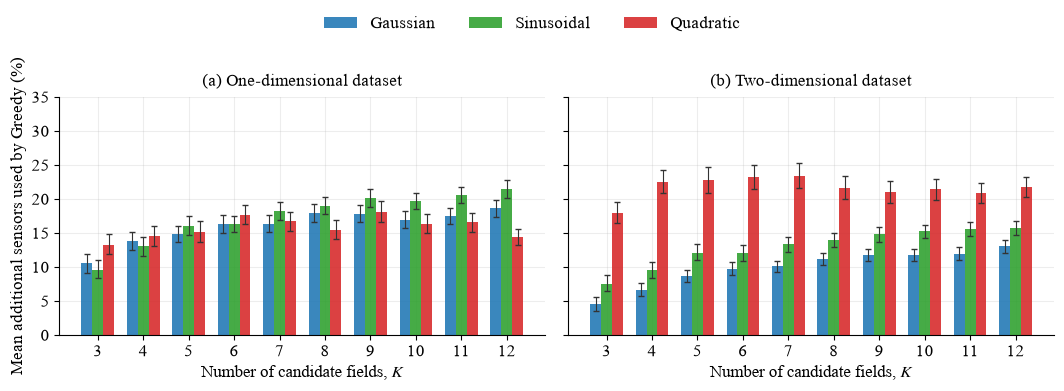

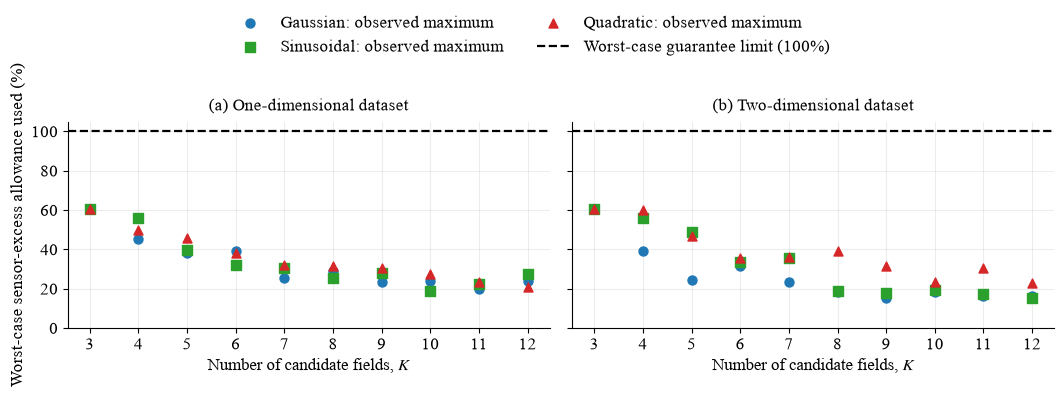

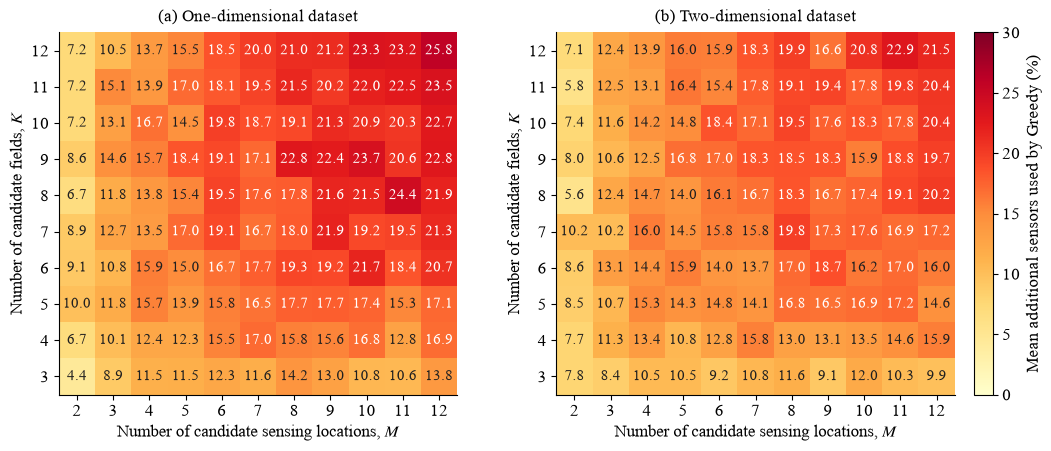

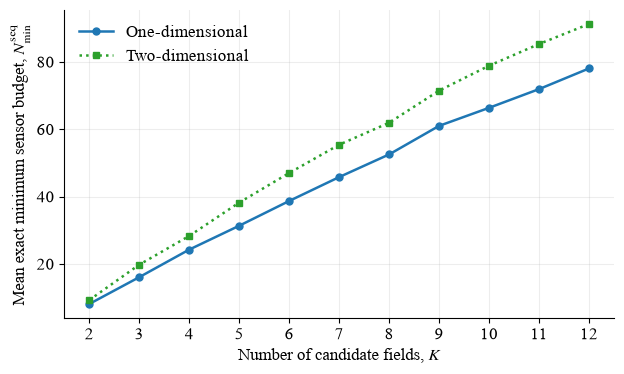

Saved final figures under: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/results/final


In [31]:
figure_1 = plot_family_excess(family_rows)
save_figure(figure_1, "figure_1_zero_error_family_excess")
display_or_close(figure_1)

figure_2 = plot_guarantee(guarantee_table_rows)
save_figure(figure_2, "figure_2_zero_error_guarantee")
display_or_close(figure_2)

figure_3 = plot_quality_heatmaps(heatmap_table_rows)
save_figure(figure_3, "figure_3_zero_error_quality_heatmaps")
display_or_close(figure_3)

figure_4 = plot_minimum_sensor_budget(nmin_table_rows)
save_figure(figure_4, "figure_4_zero_error_minimum_sensor_budget")
display_or_close(figure_4)

print("Saved final figures under:", OUTPUT_DIRECTORY)

## Greedy Sequential vs Sequential Minimum vs Global Minimum

The global minimum is labeled $N_{\min}^{\mathrm{global}}$. All three curves average the same cases at each $K$, pooling field families and $M$. The greedy curve uses the sequential heuristic. The global minimum solves the pairwise integer constraints; the sequential optimum comes from DP. Their gap does not establish achievable global savings.

/Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-1-zero-error/src/sensor_budget_analysis.py:239: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  figure, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), sharey=True)


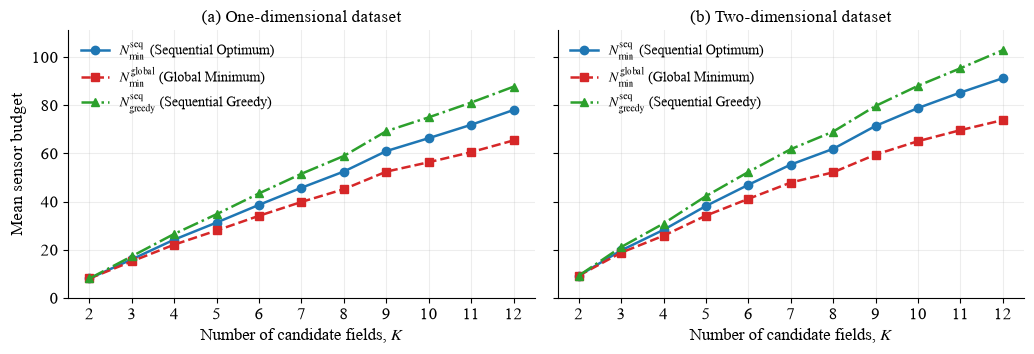

In [34]:
import sys
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))
import importlib
import sensor_budget_analysis
importlib.reload(sensor_budget_analysis)
from sensor_budget_analysis import plot_budget_comparison

if not lower_bound_rows or any("mean_N_greedy" not in row for row in lower_bound_rows):
    raise ValueError("Run updated 03 in full mode first to save all three budget curves.")

write_csv(FIGURE_DATA_DIRECTORY / "figure_5_lower_bound_comparison_data.csv", lower_bound_rows)
lower_bound_figure = plot_budget_comparison(lower_bound_rows)
for axis, dimension in zip(lower_bound_figure.axes, (1, 2)):
    axis.set_title(DIMENSION_TITLE_LABELS[dimension])
    legend_styles = (
        (r"$N_{\min}^{\mathrm{seq}}$ (Sequential Optimum)", "#1f77b4"),
        (r"$N_{\min}^{\mathrm{global}}$ (Global Minimum)", "#d62728"),
        (r"$N_{\mathrm{greedy}}^{\mathrm{seq}}$ (Sequential Greedy)", "#2ca02c"),
    )
    for line, (label, color) in zip(axis.lines, legend_styles):
        line.set_color(color)
        line.set_label(label)
    axis.legend(frameon=False, fontsize=10)
lower_bound_figure.tight_layout()
save_figure(lower_bound_figure, "figure_5_lower_bound_comparison")
display_or_close(lower_bound_figure)

## Allocation-match comparison

All field families and location counts are pooled within each dimension and $K$.
**Same allocation** means Greedy and DP return identical sensor counts at every location.
**Same total budget** means their total sensor counts agree, even if the allocations differ.

The DP can have multiple optimal allocations: a different Greedy vector may still be optimal.
Allocation agreement is measured against the particular optimum returned by this DP, not against all possible optima. The table and plot report descriptive percentages, not confidence intervals.


| Dimension | K | Cases | Allocation matches | Budget matches | Same allocation (%) | Same total budget (%) |
|---|---:|---:|---:|---:|---:|---:|
| One-dimensional | 2 | 1800 | 1035 | 1800 | 57.50 | 100.00 |
| One-dimensional | 3 | 1800 | 748 | 1135 | 41.56 | 63.06 |
| One-dimensional | 4 | 1800 | 644 | 858 | 35.78 | 47.67 |
| One-dimensional | 5 | 1800 | 516 | 679 | 28.67 | 37.72 |
| One-dimensional | 6 | 1800 | 459 | 567 | 25.50 | 31.50 |
| One-dimensional | 7 | 1800 | 434 | 511 | 24.11 | 28.39 |
| One-dimensional | 8 | 1800 | 422 | 485 | 23.44 | 26.94 |
| One-dimensional | 9 | 1800 | 393 | 436 | 21.83 | 24.22 |
| One-dimensional | 10 | 1800 | 369 | 419 | 20.50 | 23.28 |
| One-dimensional | 11 | 1800 | 352 | 392 | 19.56 | 21.78 |
| One-dimensional | 12 | 1800 | 364 | 397 | 20.22 | 22.06 |
| Two-dimensional | 2 | 1800 | 1220 | 1800 | 67.78 | 100.00 |
| Two-dimensional | 3 | 1800 | 910 | 1200 | 50.56 | 66.67 |
| Two-dimensional | 4 | 1800 | 744 | 938 | 41.33 | 52.11 |
| Two-dimensional | 5 | 1800 | 605 | 738 | 33.61 | 41.00 |
| Two-dimensional | 6 | 1800 | 555 | 653 | 30.83 | 36.28 |
| Two-dimensional | 7 | 1800 | 468 | 565 | 26.00 | 31.39 |
| Two-dimensional | 8 | 1800 | 436 | 514 | 24.22 | 28.56 |
| Two-dimensional | 9 | 1800 | 408 | 474 | 22.67 | 26.33 |
| Two-dimensional | 10 | 1800 | 377 | 421 | 20.94 | 23.39 |
| Two-dimensional | 11 | 1800 | 376 | 422 | 20.89 | 23.44 |
| Two-dimensional | 12 | 1800 | 355 | 396 | 19.72 | 22.00 |

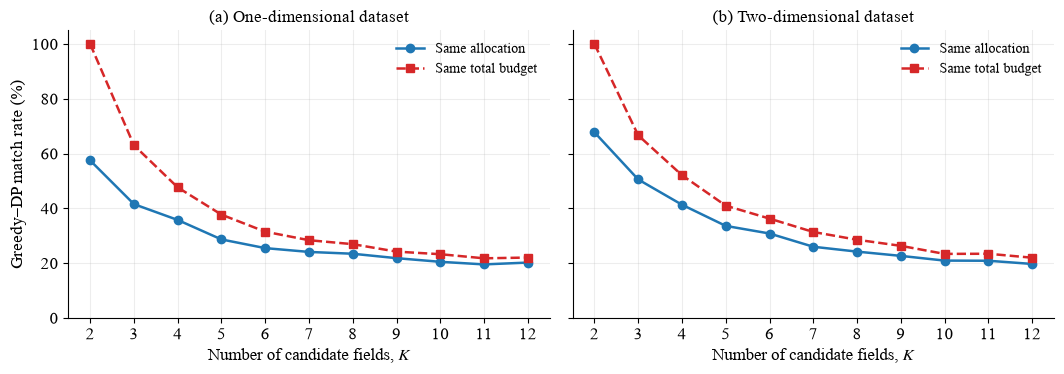

In [33]:
from benchmark_analysis import plot_allocation_match

MATCH_TABLE_PATH = TABLES_DIRECTORY / "allocation_match.csv"
if not MATCH_TABLE_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {MATCH_TABLE_PATH}. Run the updated 01_solution_method_analysis.ipynb in full mode first."
    )
match_rows = read_csv(MATCH_TABLE_PATH)
write_csv(FIGURE_DATA_DIRECTORY / "figure_6_allocation_match_data.csv", match_rows)
display(Markdown(markdown_table(
    match_rows,
    (("Dimension", "dimension"), ("K", "K"), ("Cases", "case_count"),
     ("Allocation matches", "allocation_matches"), ("Budget matches", "budget_matches"),
     ("Same allocation (%)", "allocation_match_percent"),
     ("Same total budget (%)", "budget_match_percent")),
    {"K": lambda x: str(int(x)), "case_count": lambda x: str(int(x)),
     "allocation_matches": lambda x: str(int(x)), "budget_matches": lambda x: str(int(x)),
     "allocation_match_percent": lambda x: f"{float(x):.2f}",
     "budget_match_percent": lambda x: f"{float(x):.2f}"},
)))
match_figure = plot_allocation_match(match_rows)
for axis, dimension in zip(match_figure.axes, (1, 2)):
    axis.set_title(DIMENSION_TITLE_LABELS[dimension])
    for line, color in zip(axis.lines, ("#1f77b4", "#d62728")):
        line.set_color(color)
    axis.legend(frameon=False, fontsize=10)
match_figure.tight_layout()
save_figure(match_figure, "figure_6_allocation_match")
display_or_close(match_figure)
